In [1]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated
import operator
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage, AIMessage
from langchain_openai import ChatOpenAI
from langchain_community.tools.tavily_search import TavilySearchResults
from openai import OpenAI
import os
import re
import json
import uuid

/tmp/ipykernel_15715/2661538777.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [2]:
import os
import keyword
from dotenv import load_dotenv

_ = load_dotenv(".env")

globals().update({
    key: os.environ[key]
    for key in os.environ.keys()
    if key.isidentifier() and not keyword.iskeyword(key)
})

In [3]:
tool = TavilySearchResults(max_results=4) #increased number of results
print(type(tool))
print(tool.name)

<class 'langchain_community.tools.tavily_search.tool.TavilySearchResults'>
tavily_search_results_json


/tmp/ipykernel_15715/144666821.py:1: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tool = TavilySearchResults(max_results=4) #increased number of results


In [4]:
result = tool.invoke({
    "query": "What is LangGraph?"
})
for i in result:
    print(i)

{'title': 'Understanding LangGraph Data Visualization Software | Coursera', 'url': 'https://www.coursera.org/articles/langgraph', 'content': '## What is LangGraph?\n\nLangGraph is an open-source library within the LangChain ecosystem that enables developers to build multi-agent applications using large language models (LLMs). While traditional AI workflows are often linear and rigid, LangGraph uses graph-based architectures to manage complex relationships between components. LangGraph provides a flexible way to coordinate and execute multiple LLM “agents” in complex workflows; by using "cycles" and "state management", it allows AI agents to solve large-scale problems that require iterative reasoning and human-like step-by-step logic.\n\n## 3 key features of LangGraph\n\n1. Graph-based Structure: Retains information across stages, making it easy to add conditional steps or "memory" to a chatbot. [...] LangGraph enables developers to coordinate and execute multiple LLM agents through gra

In [5]:
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

In [6]:
class Agent:

    def __init__(self, model, tools, system=""):
        self.system = system
        graph = StateGraph(AgentState)
        graph.add_node("llm", self.call_openai)
        graph.add_node("action", self.take_action)
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END}
        )
        graph.add_edge("action", "llm")
        graph.set_entry_point("llm")
        self.graph = graph.compile()
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    def exists_action(self, state: AgentState):
        print("exists_action called")
        result = state['messages'][-1]
        return len(result.tool_calls) > 0

    def call_openai(self, state: AgentState):
        print("call_openai called")
        messages = state['messages']
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        # message = self.normalize_tool_call(message)
        return {'messages': [message]}

    def take_action(self, state: AgentState):
        print("take_action called")
        tool_calls = state['messages'][-1].tool_calls
        results = []
        for t in tool_calls:
            print(f"Calling: {t}")
            if not t['name'] in self.tools:      # check for bad tool name from LLM
                print("\n ....bad tool name....")
                result = "bad tool name, retry"  # instruct LLM to retry if bad
            else:
                result = self.tools[t['name']].invoke(t['args'])
            results.append(ToolMessage(tool_call_id=t['id'], name=t['name'], content=str(result)))
        print("Back to the model!")
        return {'messages': results}

    def normalize_tool_call(self, message: AIMessage) -> AIMessage:
        # Already a structured tool call: leave it unchanged.
        if message.tool_calls or not isinstance(message.content, str):
            return message

        # Find a JSON object inside a fenced code block.
        match = re.search(
            r"```json\s*(.*?)\s*```",
            message.content,
            re.DOTALL | re.IGNORECASE,
        )
        if not match:
            return message

        try:
            payload = json.loads(match.group(1))
            name = payload["name"]
            args = payload["arguments"]

            # Only permit tools explicitly registered by the application.
            if name not in self.tools or not isinstance(args, dict):
                return message

            # # Validate the arguments against the tool's declared schema.
            validated_args = self.tools[name].args_schema.model_validate(args)

            return AIMessage(
                content="",
                tool_calls=[
                    {
                        "name": name,
                        "args": validated_args.model_dump(),
                        "id": f"call_{uuid.uuid4().hex}",
                        "type": "tool_call",
                    }
                ],
            )

        except (ValueError, KeyError, TypeError, AttributeError):
            # Leave malformed or invalid output unchanged.
            return message

In [7]:
prompt = """You are a smart research assistant. Use the search engine to look up information. \
You are allowed to make multiple calls (either together or in sequence). \
Only look up information when you are sure of what you want. \
If you need to look up some information before asking a follow up question, you are allowed to do that!
"""

# model = ChatOpenAI(
#     model="qwen2.5-coder-7b:latest",
#     base_url="http://localhost:11434/v1",
#     api_key="ollama",
#     temperature=0,
#     )


# model = ChatOpenAI(
#     model="gpt-5-mini",
#     openai_proxy="socks5://127.0.0.1:2341",
#     # api_key is read from OPENAI_API_KEY
# )

model = ChatOpenAI(
    model=DEEPSEEK_MODEL,
    base_url=DEEPSEEK_BASE_URL,
    api_key=DEEPSEEK_API_KEY
    # api_key is read from OPENAI_API_KEY
)

response = model.invoke("Hello")
print(response)

content='Hello! How can I help you today?' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 28, 'prompt_tokens': 31, 'total_tokens': 59, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 18, 'rejected_prediction_tokens': None, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 31}, 'model_provider': 'openai', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '59dc61e0-b233-44b4-9e7b-2bcea013de0a', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--01a1cb02-fd38-7022-9412-f52d4294759d-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 31, 'output_tokens': 28, 'total_tokens': 59, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoni

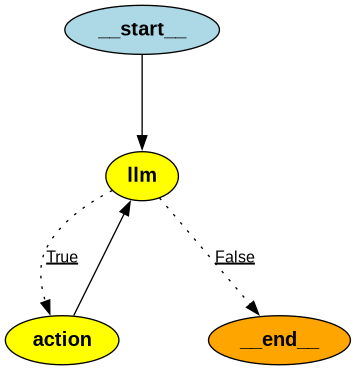

In [8]:
from IPython.display import Image

abot = Agent(model, [tool], system=prompt)


Image(abot.graph.get_graph().draw_png())

In [9]:
messages = [HumanMessage(content="What is the weather in sf?")]
result = abot.graph.invoke({"messages": messages})

call_openai called
exists_action called
take_action called
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather in San Francisco today'}, 'id': 'call_00_KHLccCd8r1kh19k0xO1b4826', 'type': 'tool_call'}
Back to the model!
call_openai called
exists_action called


In [10]:
for m in result['messages']:
    print(type(m))
    print(m.content)
    if isinstance(m, AIMessage):
        print(m.tool_calls if hasattr(m, 'tool_calls') else "")

<class 'langchain_core.messages.human.HumanMessage'>
What is the weather in sf?
<class 'langchain_core.messages.ai.AIMessage'>

[{'name': 'tavily_search_results_json', 'args': {'query': 'current weather in San Francisco today'}, 'id': 'call_00_KHLccCd8r1kh19k0xO1b4826', 'type': 'tool_call'}]
<class 'langchain_core.messages.tool.ToolMessage'>
[{'title': 'San Francisco - Wikipedia', 'url': 'https://en.wikipedia.org/wiki/San_Francisco', 'content': '### Climate\nSan Francisco falls under the USDA Plant hardiness zone 10a and 10b.()()\n|  v  t  e Climate data for San Francisco (downtown),() 1991–2020 normals,() extremes 1849–present |\n| --- |\n| Month | Jan | Feb | Mar | Apr | May | Jun | Jul | Aug | Sep | Oct | Nov | Dec | Year |\n| Record high °F (°C) | 79 (26) | 81 (27) | 90 (32) | 94 (34) | 97 (36) | 103 (39) | 99 (37) | 98 (37) | 106 (41) | 102 (39) | 86 (30) | 76 (24) | 106 (41) |\n| Mean maximum °F (°C) | 67.1 (19.5) | 71.8 (22.1) | 76.4 (24.7) | 80.7 (27.1) | 81.4 (27.4) | 84.6 (29

In [11]:
messages = [HumanMessage(content="What is the weather in SF and LA?")]
result = abot.graph.invoke({"messages": messages})

call_openai called
exists_action called
take_action called
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather San Francisco CA'}, 'id': 'call_00_QCoGlIlSHhsFyo6HUzCK7729', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather Los Angeles CA'}, 'id': 'call_01_uggDwdwwmVovOpeSn5aB9189', 'type': 'tool_call'}
Back to the model!
call_openai called
exists_action called
take_action called
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'National Weather Service current conditions San Francisco downtown forecast'}, 'id': 'call_00_RFHD4RnfoidU5O4w07kI1688', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'National Weather Service current conditions Los Angeles downtown forecast'}, 'id': 'call_01_00vIXob7HE3ZVWl2nu0g7667', 'type': 'tool_call'}
Back to the model!
call_openai called
exists_action called


In [12]:
print(result['messages'][-1].content)
print(result['messages'][-1].tool_calls)

Assuming San Francisco and Los Angeles, California:

- **San Francisco:** Clear and **~54°F (12°C)** early this morning; sunny later with a high around **68°F (20°C)**.
- **Los Angeles:** Clear and **~64°F (18°C)** early this morning; sunny and very warm with a high near **86°F (30°C)**.

San Francisco can vary a lot by neighborhood, especially near the coast.
[]


In [13]:
# Note, the query was modified to produce more consistent results. 
# Results may vary per run and over time as search information and models change.
abot = Agent(model, [tool], system=prompt)
query = "Who won the super bowl in 2026? In what state is the winning team headquarters located? \
What is the GDP of that state? Answer each question." 
messages = [HumanMessage(content=query)]
 # requires more advanced model
abot = Agent(model, [tool], system=prompt)
result = abot.graph.invoke({"messages": messages})

call_openai called
exists_action called
take_action called
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Super Bowl 2026 winner'}, 'id': 'call_00_SrBpllfzXdxpYkg16YB23229', 'type': 'tool_call'}
Back to the model!
call_openai called
exists_action called
take_action called
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Washington state GDP 2025 nominal'}, 'id': 'call_00_Y8yheBr3sz1u3bzHmaSj0100', 'type': 'tool_call'}
Back to the model!
call_openai called
exists_action called


In [14]:
for m in result['messages']:
    print(type(m))
    print(m.content)
    if isinstance(m, AIMessage):
        if hasattr(m, 'tool_calls'):
            for i in m.tool_calls:
                print(i) 
        else:
            print("no tool calls")
    # if isinstance(m, ToolMessage):
    #     print(m.name, m.content)
    print("\n")

<class 'langchain_core.messages.human.HumanMessage'>
Who won the super bowl in 2026? In what state is the winning team headquarters located? What is the GDP of that state? Answer each question.


<class 'langchain_core.messages.ai.AIMessage'>

{'name': 'tavily_search_results_json', 'args': {'query': 'Super Bowl 2026 winner'}, 'id': 'call_00_SrBpllfzXdxpYkg16YB23229', 'type': 'tool_call'}


<class 'langchain_core.messages.tool.ToolMessage'>
[{'title': 'Super Bowl Winners by Year - ESPN', 'url': 'http://www.espn.com/nfl/superbowl/history/winners', 'content': "| LIII | Feb. 3, 2019 | Mercedes-Benz Stadium (Atlanta) | New England 13, Los Angeles Rams 3 |\n| LIV | Feb. 2, 2020 | Hard Rock Stadium (Miami) | Kansas City 31, San Francisco 20 |\n| LV | Feb. 7, 2021 | Raymond James Stadium (Tampa, Fla.) | Tampa Bay 31, Kansas City 9 |\n| LVI | Feb. 13, 2022 | SoFi Stadium (Inglewood, Calif.) | Los Angeles Rams 23, Cincinnati 20 |\n| LVII | Feb. 12, 2023 | State Farm Stadium (Glendale, Ariz.) | K